<a href="https://colab.research.google.com/github/srikanthmuppuri66-maker/CodeAlpha_Unemployment_Analysis/blob/main/CodeAlpha_Unemployment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
print(os.listdir("/content"))

['.config', 'Unemployment in India.csv', 'sample_data']


In [2]:
import pandas as pd

# Load the unemployment dataset
df = pd.read_csv("/content/Unemployment in India.csv")

# Display the first 5 rows
print("First 5 rows of the dataset:")
display(df.head())

# Display dataset information
print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

First 5 rows of the dataset:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural



Dataset shape:
(768, 7)

Column names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Missing values:
Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64


In [3]:
# Remove rows with missing values
df = df.dropna()

# Check the dataset after cleaning
print("Dataset shape after cleaning:", df.shape)

# Check missing values
print("\nMissing values after cleaning:")
print(df.isnull().sum())

# Display first 5 rows
df.head()

Dataset shape after cleaning: (740, 7)

Missing values after cleaning:
Region                                      0
 Date                                       0
 Frequency                                  0
 Estimated Unemployment Rate (%)            0
 Estimated Employed                         0
 Estimated Labour Participation Rate (%)    0
Area                                        0
dtype: int64


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [5]:
# Convert Date column to datetime format
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

# Check the date format
print(df['Date'].head())

# Check column data types
print("\nColumn data types:")
print(df.dtypes)

KeyError: 'Date'

In [6]:
# Display the actual column names
print(df.columns.tolist())

['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']


In [7]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Check the column names
print(df.columns.tolist())

['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']


In [8]:
# Convert Date column to datetime format
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

# Display dates and data types
print(df['Date'].head())
print(df.dtypes)

0   2019-05-31
1   2019-06-30
2   2019-07-31
3   2019-08-31
4   2019-09-30
Name: Date, dtype: datetime64[ns]
Region                                             object
Date                                       datetime64[ns]
Frequency                                          object
Estimated Unemployment Rate (%)                   float64
Estimated Employed                                float64
Estimated Labour Participation Rate (%)           float64
Area                                               object
dtype: object


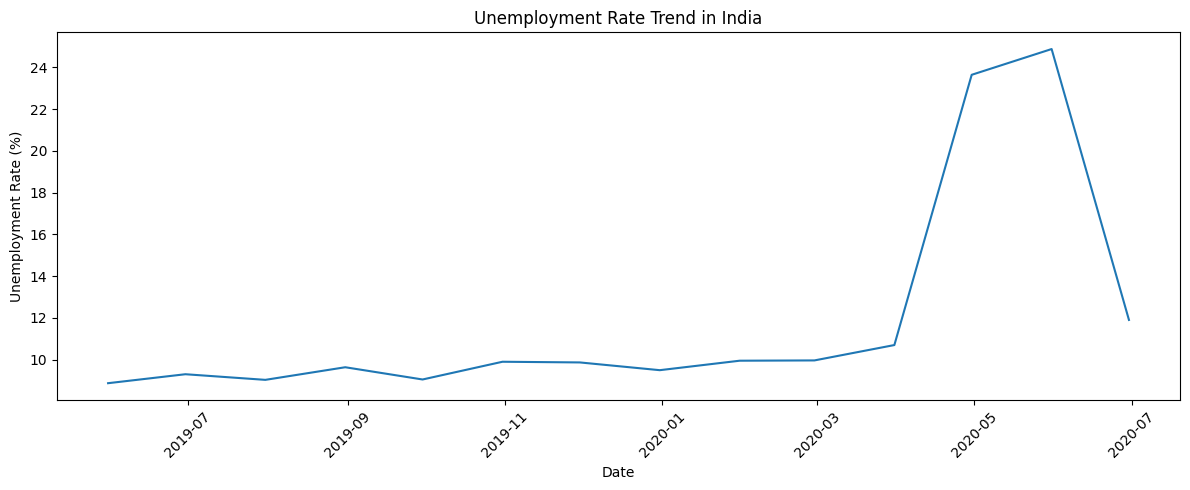

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate average unemployment rate by date
date_trend = df.groupby('Date')[
    'Estimated Unemployment Rate (%)'
].mean().reset_index()

# Plot unemployment trend
plt.figure(figsize=(12, 5))
sns.lineplot(
    data=date_trend,
    x='Date',
    y='Estimated Unemployment Rate (%)'
)

plt.title('Unemployment Rate Trend in India')
plt.xlabel('Date')
plt.ylabel('Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

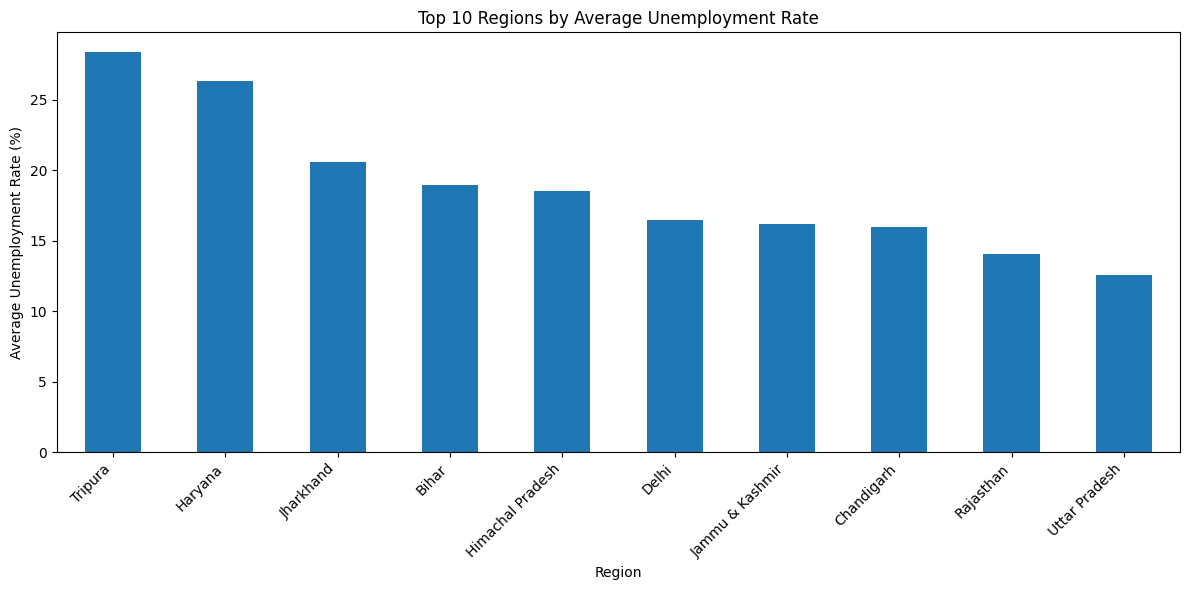

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Average unemployment rate by region
region_unemployment = df.groupby('Region')[
    'Estimated Unemployment Rate (%)'
].mean().sort_values(ascending=False)

# Plot the top 10 regions
plt.figure(figsize=(12, 6))
region_unemployment.head(10).plot(kind='bar')

plt.title('Top 10 Regions by Average Unemployment Rate')
plt.xlabel('Region')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

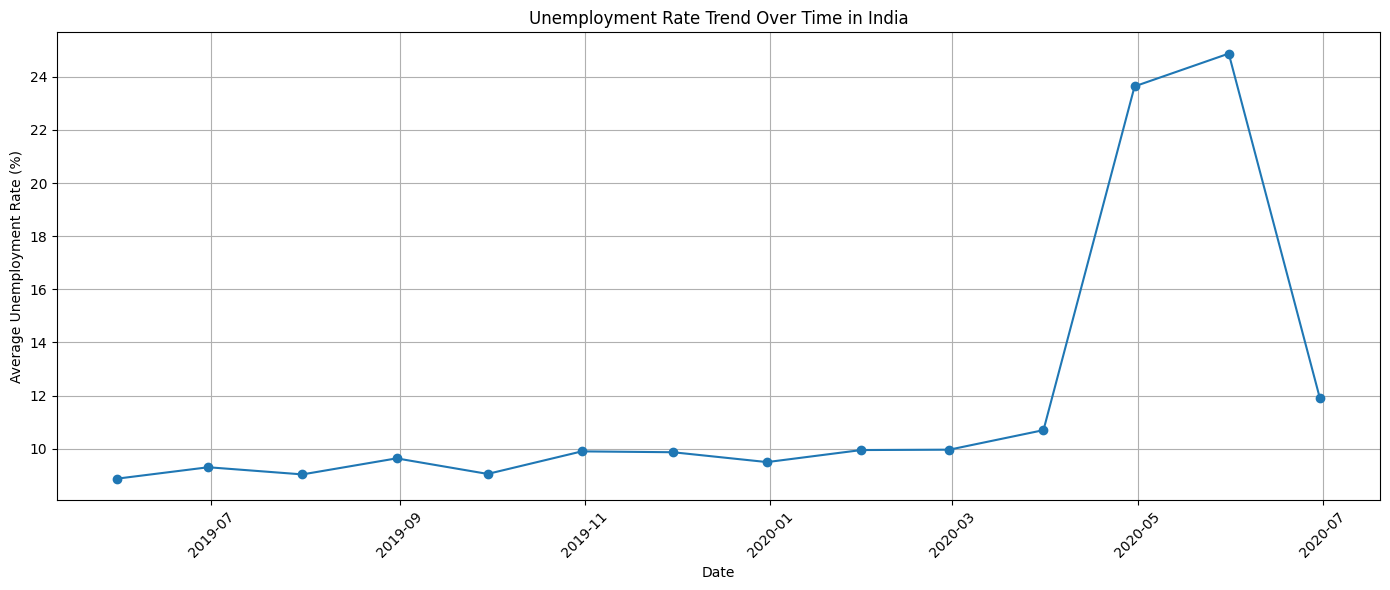

In [11]:
# Calculate average unemployment rate by date
time_trend = df.groupby('Date')[
    'Estimated Unemployment Rate (%)'
].mean().sort_index()

# Plot unemployment trend over time
plt.figure(figsize=(14, 6))
plt.plot(time_trend.index, time_trend.values, marker='o')

plt.title('Unemployment Rate Trend Over Time in India')
plt.xlabel('Date')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

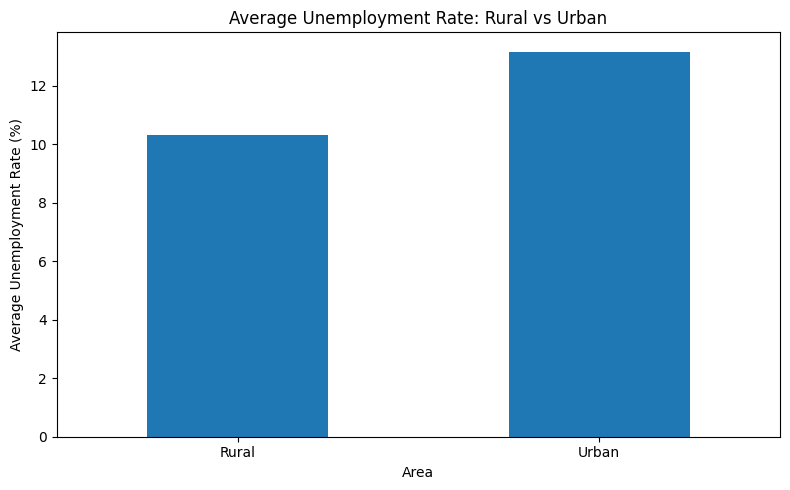

In [12]:
# Calculate average unemployment rate by area
area_unemployment = df.groupby('Area')[
    'Estimated Unemployment Rate (%)'
].mean()

# Plot comparison
plt.figure(figsize=(8, 5))
area_unemployment.plot(kind='bar')

plt.title('Average Unemployment Rate: Rural vs Urban')
plt.xlabel('Area')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
# Get the top 10 records with the highest unemployment rates
top_unemployment = df.nlargest(
    10, 'Estimated Unemployment Rate (%)'
)

# Display selected columns
display(top_unemployment[
    ['Region', 'Date', 'Estimated Unemployment Rate (%)', 'Area']
])

,Region,Date,Estimated Unemployment Rate (%),Area
627,Puducherry,2020-04-30,76.74,Urban
628,Puducherry,2020-05-31,75.00,Urban
242,Puducherry,2020-04-30,74.51,Rural
531,Jharkhand,2020-05-31,70.17,Urban
530,Jharkhand,2020-04-30,61.48,Urban
412,Bihar,2020-04-30,58.77,Urban
145,Jharkhand,2020-05-31,55.10,Rural
287,Tamil Nadu,2020-04-30,53.19,Rural
507,Himachal Pradesh,2020-05-31,50.00,Urban
38,Bihar,2020-05-31,47.26,Rural


Average unemployment rate by period:
Period
Before COVID-19     9.509534
During COVID-19    17.774363
Name: Estimated Unemployment Rate (%), dtype: float64


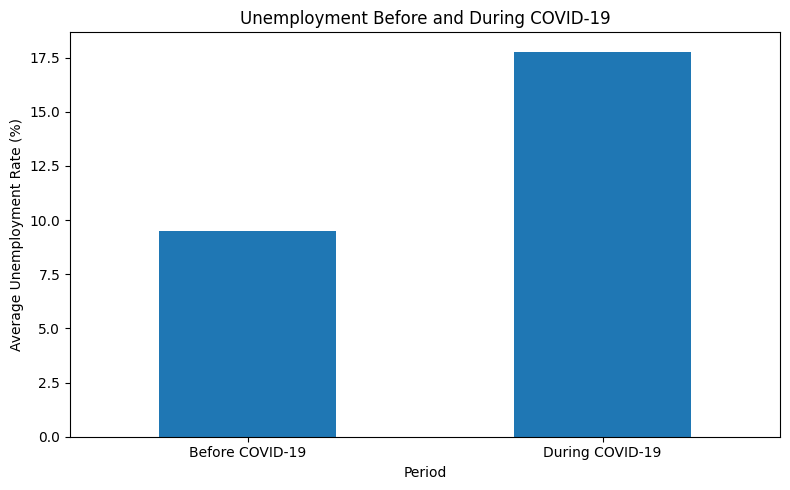

In [14]:
# Create a period column based on the date
df['Period'] = df['Date'].apply(
    lambda date: 'Before COVID-19'
    if date < pd.Timestamp('2020-03-01')
    else 'During COVID-19'
)

# Calculate average unemployment rate by period
covid_analysis = df.groupby('Period')[
    'Estimated Unemployment Rate (%)'
].mean()

print("Average unemployment rate by period:")
print(covid_analysis)

# Plot comparison
plt.figure(figsize=(8, 5))
covid_analysis.plot(kind='bar')

plt.title('Unemployment Before and During COVID-19')
plt.xlabel('Period')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Key Findings and Conclusion

- The dataset contains unemployment information across different regions of India.
- Missing values were removed during data cleaning.
- The analysis examined unemployment trends over time.
- Regional comparisons highlighted differences in average unemployment rates.
- Rural and urban unemployment rates were compared.
- The highest unemployment observations were identified.
- Average unemployment rates before and during the COVID-19 period were compared.

Conclusion

This project uses Python, Pandas, Matplotlib, and Seaborn to clean, analyze, and visualize unemployment data in India. The visualizations help identify regional differences and changes in unemployment over time, including differences between the periods before and during COVID-19.